In [1]:
#import all library
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [6]:
#step 2 -load dataset
df=pd.read_csv("experience_salary_5000.csv")

In [7]:
df

,Experience,Salary
0,7.49,55422
1,19.01,97398
2,14.64,88613
3,11.97,83889
4,3.12,41997
...,...,...
4995,17.95,118100
4996,2.39,38375
4997,6.56,53677
4998,16.31,106179


In [10]:
#understand the dataset
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())

   Experience  Salary
0        7.49   55422
1       19.01   97398
2       14.64   88613
3       11.97   83889
4        3.12   41997
      Experience  Salary
4995       17.95  118100
4996        2.39   38375
4997        6.56   53677
4998       16.31  106179
4999       11.95   88905
(5000, 2)
Index(['Experience', 'Salary'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Experience  5000 non-null   float64
 1   Salary      5000 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 78.3 KB
None
        Experience         Salary
count  5000.000000    5000.000000
mean      9.936576   69619.019600
std       5.792694   26504.258095
min       0.000000   18000.000000
25%       4.877500   47078.500000
50%      10.000000   69348.500000
75%      14.960000   91982.750000
max      19.990000  129210.000000


In [11]:
#check  null value
df.isnull().sum()

Experience    0
Salary        0
dtype: int64

In [12]:
len(df)

5000

In [19]:
#find the outliers
#select numerical column
num_cols=df.select_dtypes(include="number").columns
for i in num_cols:
    Q1=df[i].quantile(0.25)
    Q3=df[i].quantile(0.75)
    IQR=Q3-Q1

    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR

    count= ((df[i]<lower) | (df[i]>upper)).sum()
    print(i, "Outliers:",count)

Experience Outliers: 0
Salary Outliers: 0


In [22]:
#handlin capping
num_cols = df.select_dtypes(include="number").columns

for i in num_cols:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[i] = df[i].clip(lower=lower, upper=upper)

print("Outliers handled successfully!")
        
             

Outliers handled successfully!


In [23]:
for i in num_cols:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[i] < lower) | (df[i] > upper)).sum()

    print(i, "Outliers:", count)

Experience Outliers: 0
Salary Outliers: 0


<Axes: xlabel='Salary', ylabel='Density'>

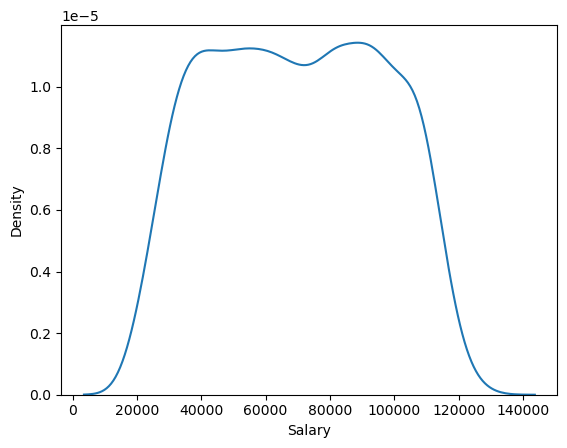

In [33]:
sns.kdeplot(data=df,x="Salary")

<Axes: xlabel='Salary', ylabel='Count'>

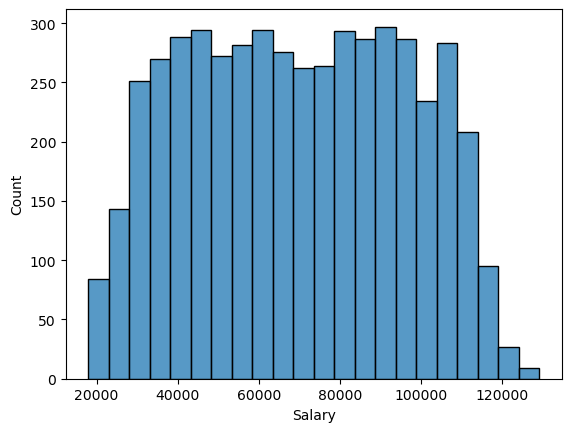

In [25]:
#step 7  check the disricution of salary
sns.histplot(data=df,x="Salary")

<Axes: xlabel='Salary', ylabel='Count'>

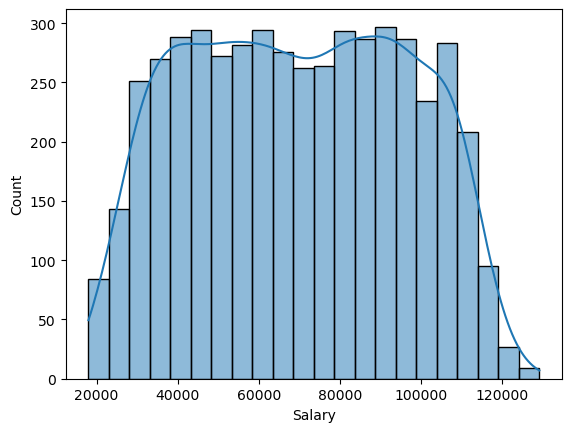

In [26]:
#step8-check the distributin of salary
sns.histplot(data=df,x="Salary",kde=True)

In [35]:
print("Mean",np.mean(df["Salary"]))
print("Median",np.median(df["Salary"]))
import statistics as st
print("Mode",st.mode(df["Salary"]))

Mean 69619.0196
Median 69348.5
Mode 18000


In [40]:
#step 8 find the relationship beetween independent and numeric data
corr=df.corr()
print(corr)
print("Strong positive correlation")

            Experience   Salary
Experience     1.00000  0.97746
Salary         0.97746  1.00000
Strong positive correlation


In [41]:
#step 8 spliting of the data
from sklearn.model_selection import train_test_split

In [43]:
X=df[["Experience"]]
y=df["Salary"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)

In [44]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4000, 1)
(1000, 1)
(4000,)
(1000,)


In [48]:
#step 9- train the model on training data
from sklearn.linear_model import LinearRegression
reg=LinearRegression()
reg
model=reg.fit(X_train,y_train)
model

LinearRegression()

In [49]:
#step 10- predict the model for X_test data
y_pred=model.predict(X_test)
y_pred


array([ 67566.39999999,  92352.64387213,  50654.48631107,  57007.63907252,
        53383.65756775,  82241.28806869,  70385.05228148, 112441.13394178,
        75798.65428244,  78438.3445143 ,  76469.7619685 , 111009.43754483,
        79735.81937404, 103224.58838644,  43272.30176431,  91547.31464884,
        38485.06693702,  31460.80648951,  29715.92650573,  39111.43411069,
        72801.03995133,  71950.97021564,  96334.54947613,  88191.7762185 ,
        73203.70456297,  63584.49439599,  95708.18230247,  34592.64235783,
        98303.13202193,  27747.34395993,  28776.37574523,  80585.88910972,
        30163.33162977,  46448.87814504,  92084.2007977 ,  53249.43603053,
        49938.63811259,  97050.39767461,  85999.49111068,  88012.81416888,
        54054.76525381,  57678.74675858,  67566.39999999, 103090.36684922,
       103806.2150477 ,  94142.26436831,  67834.84307442,  28284.23010878,
        56783.93651049, 114051.79238834,  90205.09927671,  90384.06132633,
       100226.97405533,  

In [52]:
#step-10 find accraccy
#1>r2-adjusted coore of determination
#2>Mse - mean square error
#3>-rmse-root mean square error
#4>-mae- mean absolute error
#error=actual-predicted value
from sklearn.metrics import r2_score
r2=r2_score(y_pred,y_test)
r2

0.9520889094184583

In [53]:
print("intercept",model.intercept_)#beta0
      

intercept 25152.394240461646


In [55]:
print("Slope",model.coef_[0])#beta1

Slope 4474.051240457024


In [58]:
#y=bo+b1*x
y=model.intercept_*model.coef_[0]*(9.58)
y

np.float64(1078067104.2461746)

In [62]:
#calculate salry for 20 year of experiance
y=model.intercept_+model.coef_[0]*(30)
y

np.float64(159373.93145417236)

Text(0.5, 1.0, 'simple linear regression')

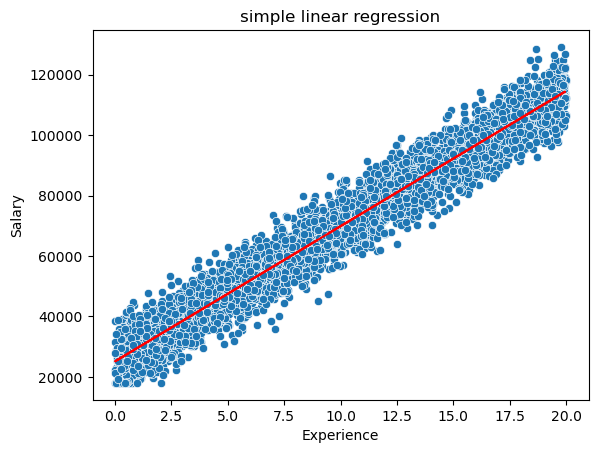

In [68]:
sns.scatterplot(data=df,x="Experience",y="Salary")
plt.plot(X_test,y_pred,color="red",label="predicted line")
plt.title("simple linear regression")